In [25]:
import numpy as np
import scanpy as sc
import scvi
import seaborn as sns

from mocavi import MoCAVIModel

scvi.settings.seed = 0
print("Last run with scvi-tools version:", scvi.__version__)

Seed set to 0


Last run with scvi-tools version: 1.1.5


In [4]:
# let's load the data
out = "data/human_vision.h5ad"
adata = sc.read_h5ad(out)
adata

AnnData object with n_obs × n_vars = 45325 × 5366
    obs: 'Total_UMI', 'Mouse_UMI', 'Human_UMI', 'Percent_Mouse_UMI', 'Percent_Human_UMI', 'Mouse_MT_UMI', 'Human_MT_UMI', 'Percent_Mouse_MT_UMI', 'Percent_Human_MT_UMI', 'Species_Annot_RNA', 'library', 'hto_label', 'ct_label', 'Total_TSB', 'Total_ADT', 'Log_Total_UMI', 'Log_Total_TSB', 'Log_Total_ADT', 'treatment', 'pathway', 'target', 'treatment_alpha', 'n_counts', 'score_s', 'score_g2m', 'donor', 'batch', '_scvi_labels', '_scvi_batch', 'leiden'
    var: 'gene_ids', 'feature_types', 'genome', 'gene_symbols', 'symbols', 'n_counts', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'highly_variable_nbatches'
    uns: '_scvi_manager_uuid', '_scvi_uuid', 'adt_select_names', 'all_to_remove', 'ct_label_colors', 'donor_colors', 'hto_label_colors', 'hvg', 'leiden', 'leiden_colors', 'library_colors', 'log1p', 'neighbors', 'pathway_colors', 'target_colors', 'totalvi_energy_distance', 'totalvi_energy_distance_null

In [6]:
# specify the baseline environment and the target environments
all_to_remove = adata.uns["all_to_remove"]
background_dataset = np.logical_or(
    adata.obs["ct_label"] == "Vehicle", np.array([x in all_to_remove for x in adata.obs["treatment"]])
)
vehicle_indices = np.where(background_dataset)[0]
target_indices = np.where(~background_dataset)[0]

INFO     Using column names from adata.uns['adt_select_names']                                                     


Anndata setup with scvi-tools version 1.1.5.

Setup via `MoCAVIModel.setup_anndata` with arguments:

{
│   'protein_expression_obsm_key': 'adt_select',
│   'protein_names_uns_key': 'adt_select_names',
│   'layer': 'counts',
│   'batch_key': 'batch',
│   'labels_key': 'treatment',
│   'categorical_covariate_keys': None,
│   'continuous_covariate_keys': None
}

         Summary Statistics         
┏━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━┓
┃     Summary Stat Key     ┃ Value ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━┩
│         n_batch          │  10   │
│         n_cells          │ 45325 │
│ n_extra_categorical_covs │   0   │
│ n_extra_continuous_covs  │   0   │
│         n_labels         │  171  │
│        n_proteins        │  83   │
│          n_vars          │ 5366  │
└──────────────────────────┴───────┘

               Data Registry                
┏━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Registry Key ┃    scvi-tools Location    ┃
┡━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│      X       │  adata.layers['counts']   │
│    batch     │ adata.obs['_scvi_batch']  │
│    labels    │ adata.obs['_scvi_labels'] │
│   proteins   │ adata.obsm['adt_select']  │
└──────────────┴───────────────────────────┘

... (6 outputs left out)

/home/lopezr55/mambaforge/envs/mocavi/lib/python3.10/site-packages/lightning/pytorch/utilities/data.py:77: Trying to infer the `batch_size` from an ambiguous collection. The batch size we found is 88. To avoid any miscalculations, use `self.log(..., batch_size=batch_size)`.


Epoch 100/100: 100%|██████████| 100/100 [14:31<00:00,  8.72s/it, v_num=1, train_loss_step=3.2e+3, train_loss_epoch=3.22e+3] 

`Trainer.fit` stopped: `max_epochs=100` reached.


Epoch 100/100: 100%|██████████| 100/100 [14:31<00:00,  8.72s/it, v_num=1, train_loss_step=3.2e+3, train_loss_epoch=3.22e+3]


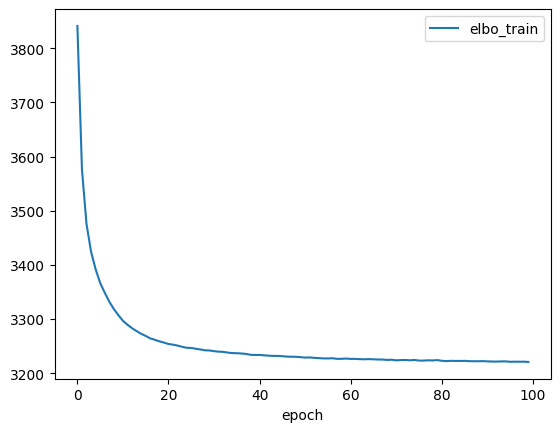

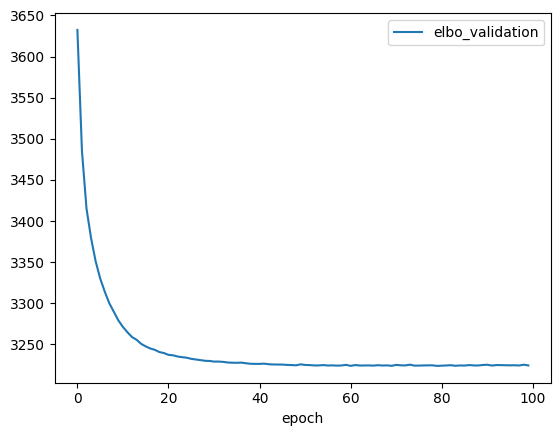

In [7]:
train = True
save_dir = "data/model"
if train:
    MoCAVIModel.setup_anndata(
        adata,
        batch_key="batch",
        labels_key="treatment",
        layer="counts",
        protein_expression_obsm_key="adt_select",
        protein_names_uns_key="adt_select_names",
    )
    # instantiate the Model
    model = MoCAVIModel(
        adata,
        n_genes=adata.n_vars,
        n_regions=0,
        n_salient_latent=15,
        n_background_latent=10,
        n_layers_decoder=2,
        reweighting_mode="auto",
    )
    # view the setup
    model.view_anndata_setup(adata)
    # train the model
    model.train(
        max_epochs=100,
        background_indices=vehicle_indices,
        target_indices=target_indices,
        check_val_every_n_epoch=1,
        early_stopping=True,
        plan_kwargs={
            "n_epochs_kl_warmup": 50,
        },
    )
    model.history["elbo_train"].plot()
    model.history["elbo_validation"].plot()
else:
    model = MoCAVIModel.load(save_dir, adata)

In [8]:
# get salient latent space
adata.obsm["salient_rep"] = model.get_latent_representation(adata, representation_kind="salient")
# umap
sc.pp.neighbors(adata, use_rep="salient_rep")
sc.tl.umap(adata)
adata.obsm["X_salient_umap"] = adata.obsm["X_umap"].copy()

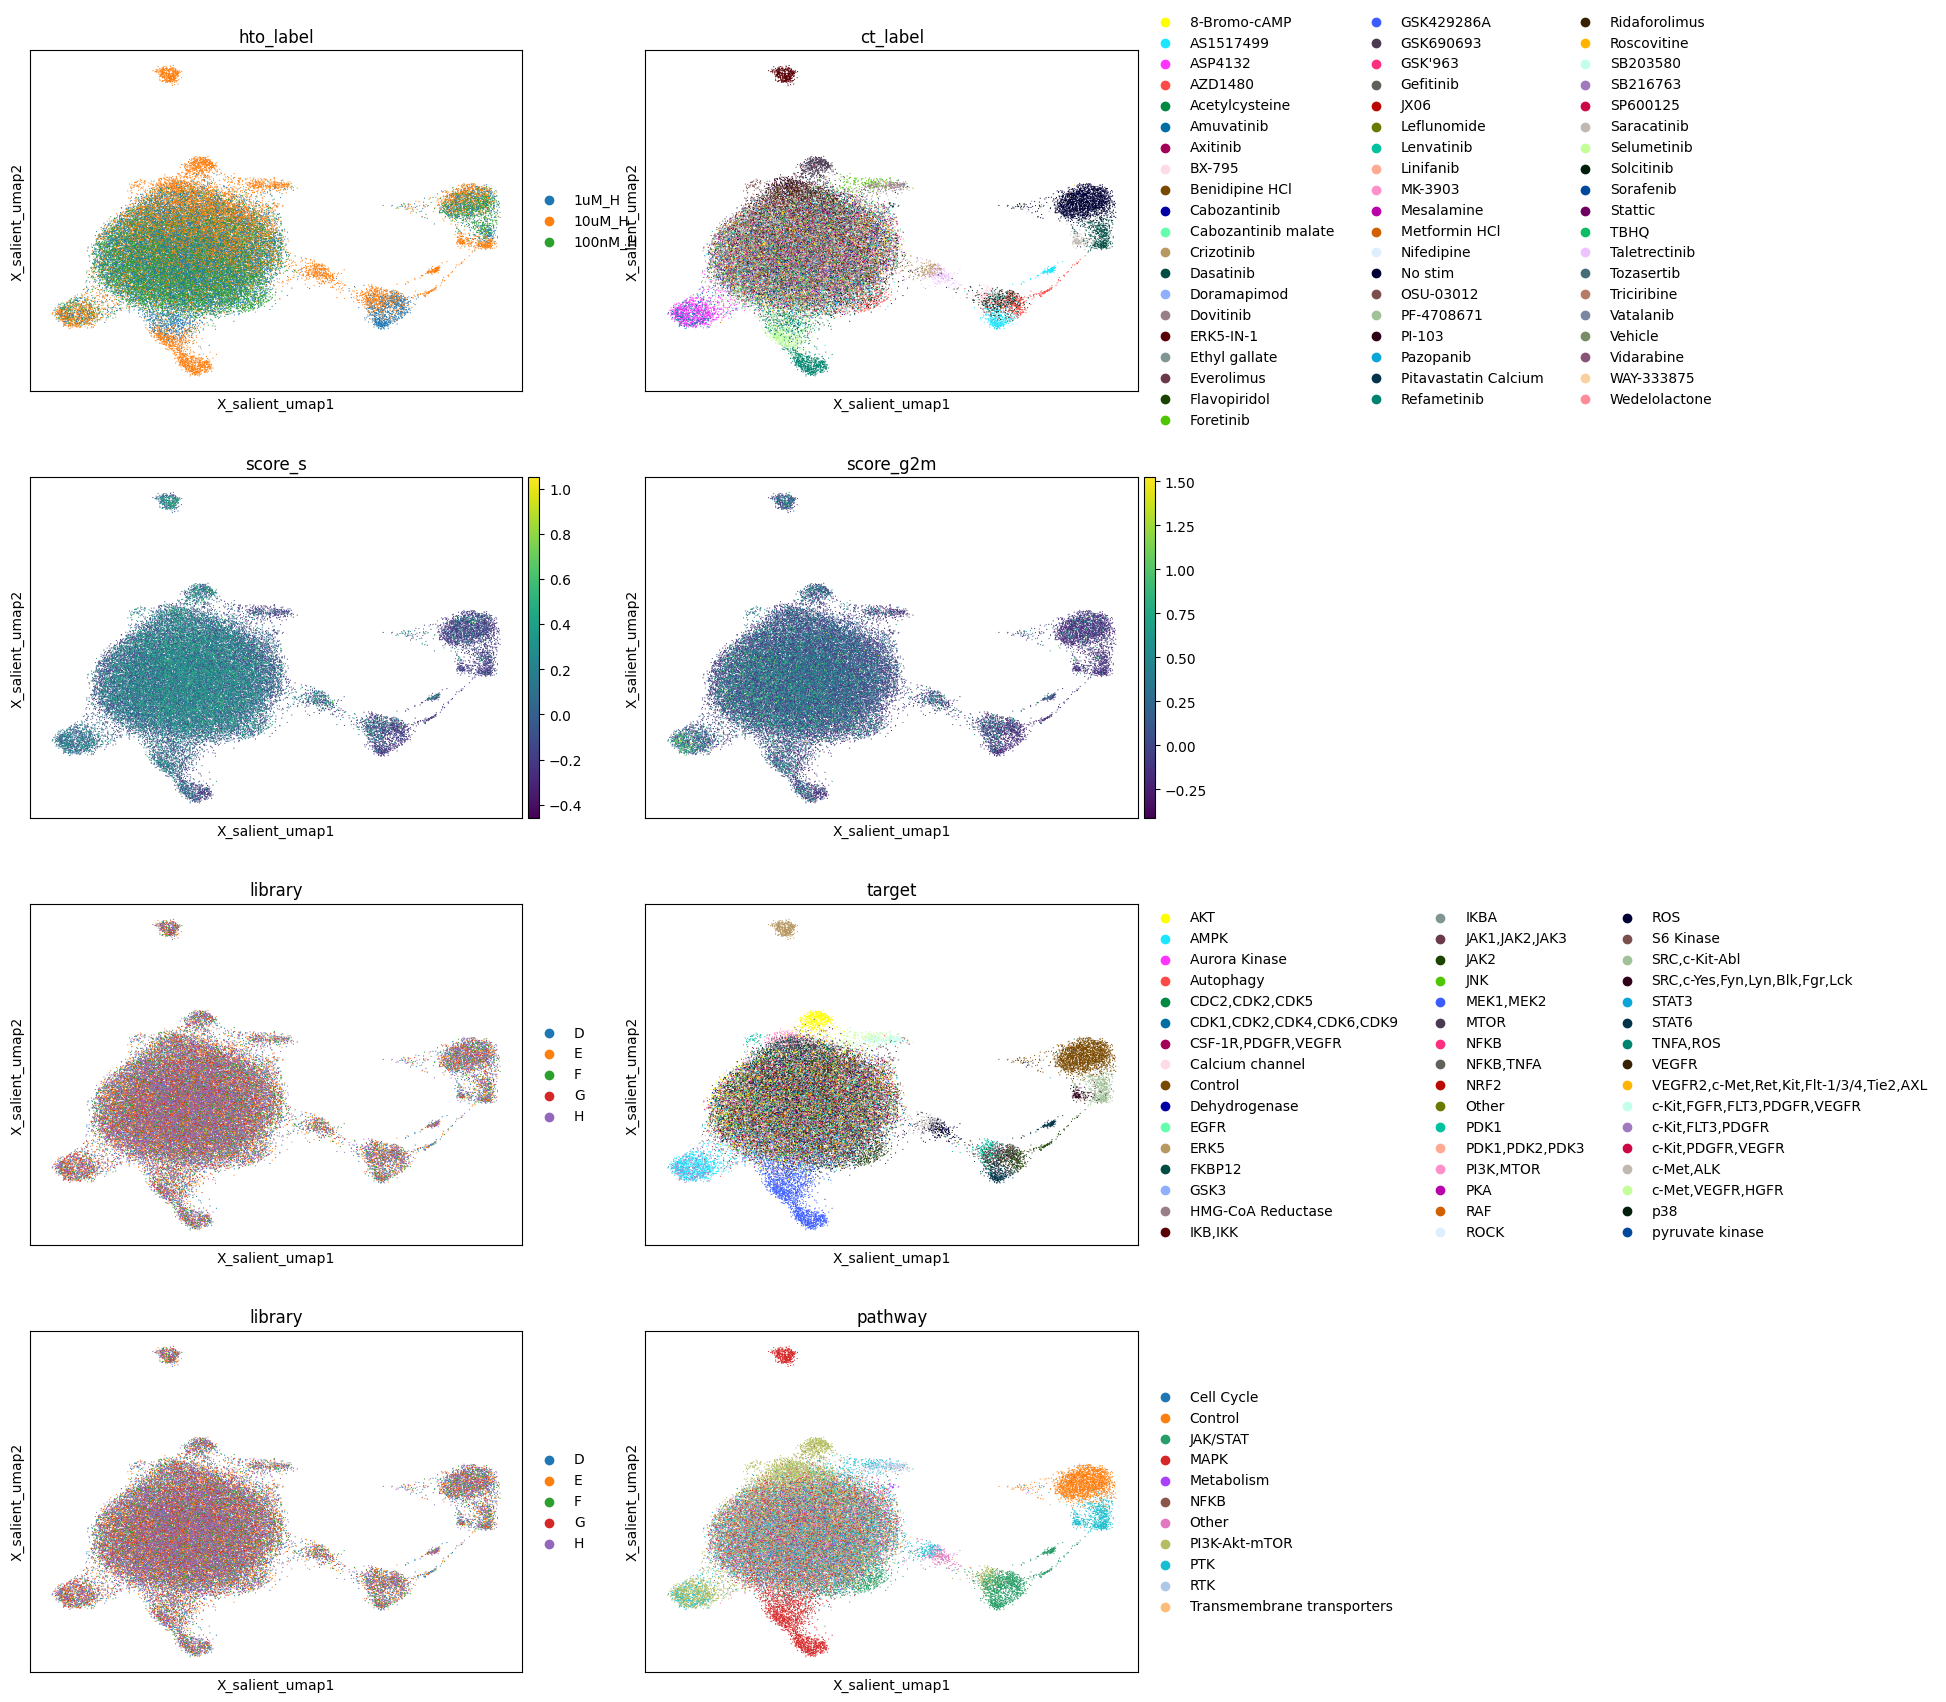

In [9]:
# quick glance at the salient latent space
sc.pl.embedding(
    adata,
    basis="X_salient_umap",
    color=["hto_label", "ct_label", "score_s", "score_g2m", "library", "target", "library", "pathway"],
    ncols=2,
)

In [14]:
adata.obs["treatment"]

AAACCCAAGATCCTAC-D        MK-3903_10uM_H
AAACCCAAGCCGGATA-D    Saracatinib_10uM_H
AAACCCAAGCTCGACC-D      Linifanib_10uM_H
AAACCCAAGGCTCACC-D     OSU-03012_100nM_H
AAACCCACAAAGAACT-D     Solcitinib_10uM_H
                             ...        
TTTGTTGCACGACGTC-H     Pazopanib_100nM_H
TTTGTTGCAGAGGCAT-H        Axitinib_1uM_H
TTTGTTGGTCCTGTCT-H       AZD1480_100nM_H
TTTGTTGTCATTCTTG-H     Saracatinib_1uM_H
TTTGTTGTCCAGTACA-H      SB203580_100nM_H
Name: treatment, Length: 45325, dtype: category
Categories (171, object): ['8-Bromo-cAMP_1uM_H', '8-Bromo-cAMP_10uM_H', '8-Bromo-cAMP_100nM_H', 'AS1517499_1uM_H', ..., 'WAY-333875_100nM_H', 'Wedelolactone_1uM_H', 'Wedelolactone_10uM_H', 'Wedelolactone_100nM_H']

In [32]:
# perform synthetic differential abundance on selected conditions
conditions_of_interest = [
    "OSU-03012_1uM_H",
    "GSK690693_10uM_H",
    "GSK690693_1uM_H",
    "Stattic_10uM_H",
    "Dovitinib_10uM_H",
    "Saracatinib_1uM_H",
    "Tozasertib_10uM_H",
    "OSU-03012_10uM_H",
    "Foretinib_10uM_H",
    "Ridaforolimus_100nM_H",
    "Ridaforolimus_1uM_H",
    "Everolimus_10uM_H",
    "Ridaforolimus_10uM_H",
    "Everolimus_1uM_H",
    "PI-103_10uM_H",
    "PI-103_1uM_H",
    "Everolimus_100nM_H",
    "Saracatinib_10uM_H",
    "No stim_10uM_H",
    "Dasatinib_10uM_H",
    "No stim_1uM_H",
    "No stim_100nM_H",
    "Dasatinib_100nM_H",
    "Dasatinib_1uM_H",
    "Selumetinib_1uM_H",
    "Refametinib_1uM_H",
    "Refametinib_10uM_H",
    "Refametinib_100nM_H",
    "Selumetinib_10uM_H",
    "PF-4708671_10uM_H",
    "Solcitinib_10uM_H",
    "AS1517499_10uM_H",
    "AS1517499_1uM_H",
    "AZD1480_1uM_H",
    "BX-795_10uM_H",
    "AZD1480_10uM_H",
    "AZD1480_100nM_H",
    "Taletrectinib_10uM_H",
    "Solcitinib_1uM_H",
    "Crizotinib_10uM_H",
    "AS1517499_100nM_H",
    "ERK5-IN-1_10uM_H",
    "Pitavastatin Calcium_10uM_H",
    "Flavopiridol_100nM_H",
    "ERK5-IN-1_1uM_H",
    "ASP4132_1uM_H",
    "ASP4132_100nM_H",
    "ASP4132_10uM_H",
    "Amuvatinib_10uM_H",
]
modality_key = "exp"
res = model.synthetic_differential_abundance(
    groupby="treatment", group1=conditions_of_interest, modality_key=modality_key
)
res["feature"] = res.index.values

DE...: 100%|██████████| 49/49 [02:24<00:00,  2.95s/it]


In [33]:
lfc_treatment = res.pivot(index="group1", columns="feature", values="lfc_median")

/home/lopezr55/mambaforge/envs/mocavi/lib/python3.10/site-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)
/home/lopezr55/mambaforge/envs/mocavi/lib/python3.10/site-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)


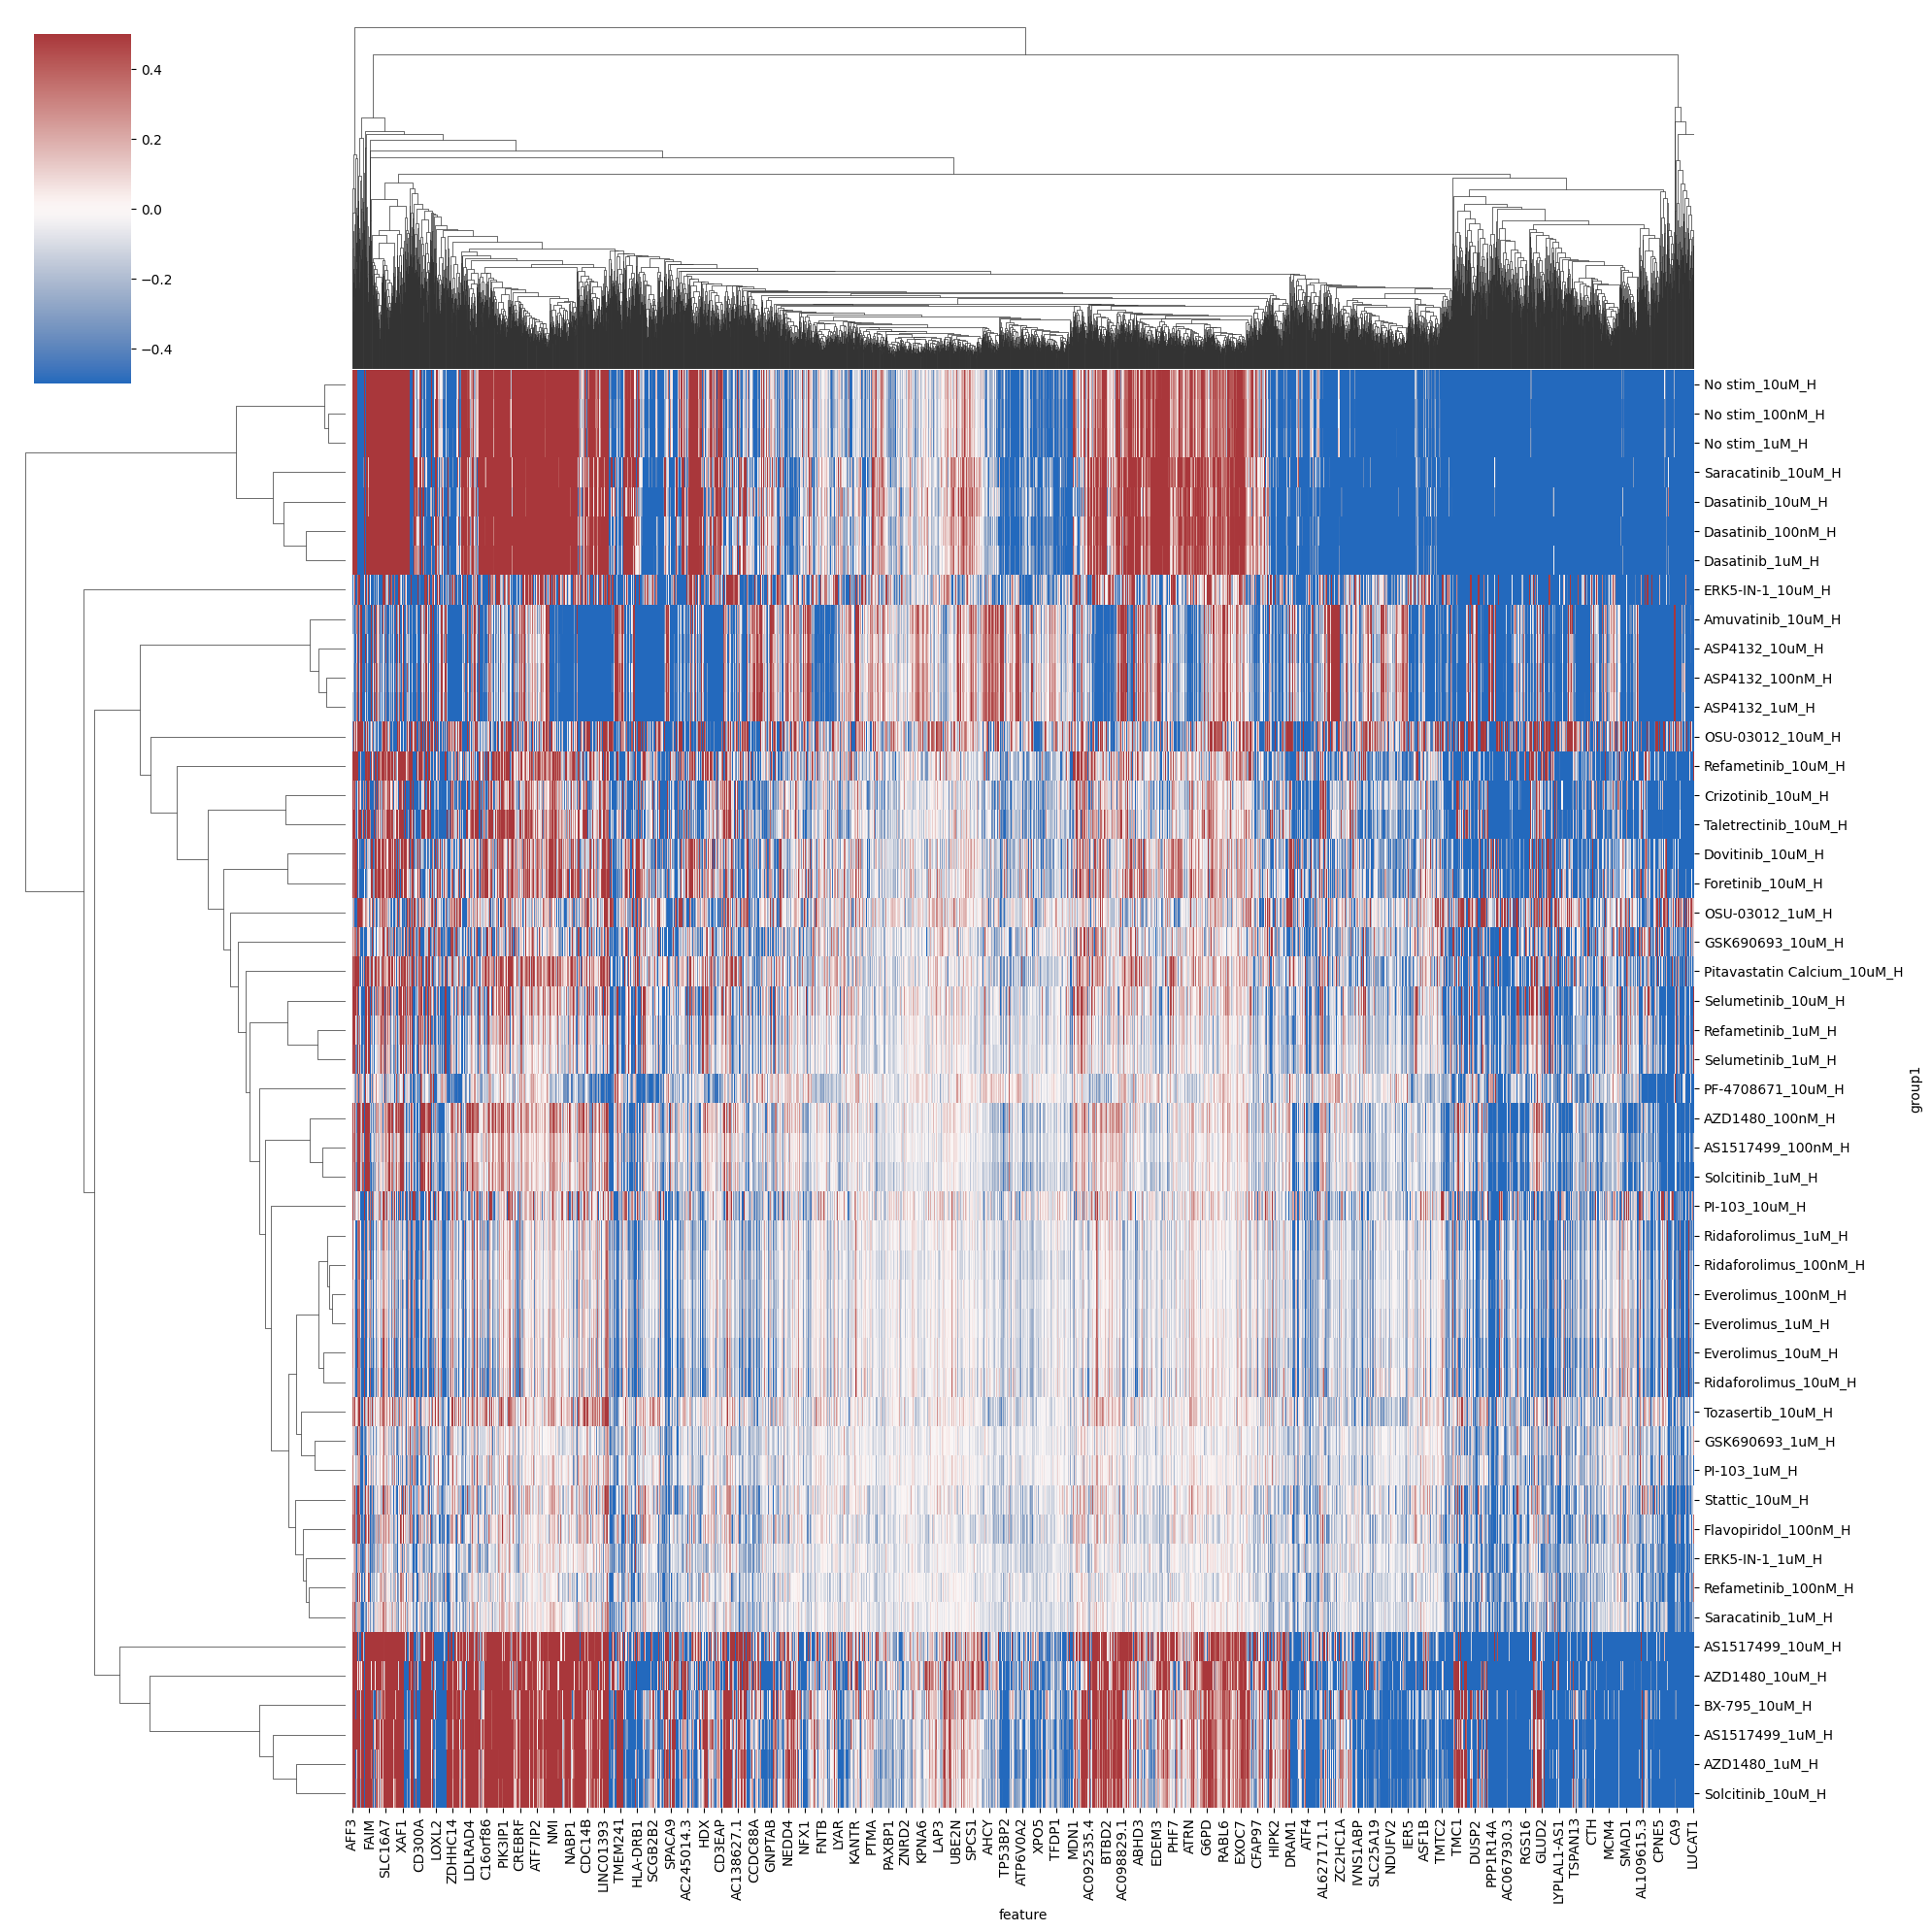

In [34]:
sns.clustermap(lfc_treatment, cmap="vlag", center=0, vmax=0.5, vmin=-0.5, figsize=(20, 20))